# L6: Hill-Climbing Loop

<p style="background-color:#fff6e4; padding:15px; border-width:3px; border-color:#f5ecda; border-style:solid; border-radius:6px"> ⏳ <b>Note <code>(Kernel Starting)</code>:</b> This notebook takes about 30 seconds to be ready to use. You may start and watch the video while you wait.</p>

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from run_history import generate_run_history
from hill_climbing import (
    propose_harness_change, load_proposal, apply_change,
    load_runs, load_summary, compare,
)
from visualization_helpers import (plot_hill_climbing_loop, 
    render_batch_overview, render_first_attempt_grid, 
    render_recurring_gaps, render_harness_change, render_comparison, 
    plot_before_after_pass_rates, render_report, render_requirement_doc,
    render_injected_feedback, render_diff,
)

%matplotlib inline
print("✓ Environment ready")

✓ Environment ready


<div style="background-color:#fff6ff; padding:13px; border-width:3px; border-color:#efe6ef; border-style:solid; border-radius:6px">
<p> 💻 &nbsp; <b>Access <code>requirements.txt</code> file:</b> 1) click on the <em>"File"</em> option on the top menu of the notebook and then 2) click on <em>"Open"</em>.</p>

<p> ⬇ &nbsp; <b>Download Notebooks:</b> 1) click on the <em>"File"</em> option on the top menu of the notebook and then 2) click on <em>"Download as"</em> and select <em>"Notebook (.ipynb)"</em>.</p>
</div>

## The Run History

In [2]:
display(render_requirement_doc("01_user_authentication"))
# display(render_requirement_doc("02_notification_system"))
# display(render_requirement_doc("03_payment_retry_policy"))
# display(render_requirement_doc("04_access_control_rules"))
# display(render_requirement_doc("05_alert_escalation_rules"))

<p style="background-color:#f7fff8; padding:15px; border-width:3px; border-color:#e0f0e0; border-style:solid; border-radius:6px"> 🚨
&nbsp; <b>Different Run Results:</b> LLMs do not always produce the same results. Consequently, the agent behavior you experience when running labs may differ from the video.</p>

In [3]:
AGENT_MODEL = "openai:gpt-5.4-mini"
ANALYST_MODEL = "openai:gpt-5.5"
USE_LIVE_LLM = True

if USE_LIVE_LLM:
    generate_run_history(label="v1_live", model=AGENT_MODEL)
    label_v1 = "v1_live"
else:
    label_v1 = "v1"

runs_v1 = load_runs(label_v1)
summary_v1 = load_summary(label_v1)

display(render_batch_overview(runs_v1, summary_v1))

[1/5] 01_user_authentication ... satisfied, first attempt failed: 0 of 3
[2/5] 02_notification_system ... satisfied, first attempt failed: 2 of 3
[3/5] 03_payment_retry_policy ... satisfied, first attempt failed: 2 of 3
[4/5] 04_access_control_rules ... satisfied, first attempt failed: 2 of 3
[5/5] 05_alert_escalation_rules ... satisfied, first attempt failed: 2 of 3


Document,Attempts
01_user_authentication,1
02_notification_system,2
03_payment_retry_policy,2
04_access_control_rules,2
05_alert_escalation_rules,2


In [4]:
display(render_first_attempt_grid(runs_v1, summary_v1))

Document,Completeness,Clarity,Depth
01_user_authentication,Pass,Pass,Pass
02_notification_system,Pass,Fail,Fail
03_payment_retry_policy,Pass,Fail,Fail
04_access_control_rules,Pass,Fail,Fail
05_alert_escalation_rules,Pass,Fail,Fail
Pass Rate,5/5,1/5,1/5


In [5]:
display(render_injected_feedback(runs_v1[0], 1, len(runs_v1)))
# display(render_injected_feedback(runs_v1[1], 2, len(runs_v1)))
# display(render_injected_feedback(runs_v1[2], 3, len(runs_v1)))
# display(render_injected_feedback(runs_v1[3], 4, len(runs_v1)))
# display(render_injected_feedback(runs_v1[4], 5, len(runs_v1)))

In [6]:
display(render_recurring_gaps(runs_v1))

Document,Gap
02_notification_system,"Each Ambiguities bullet needs an indented ""Resolved by:"" line. The file currently has only a ""Reason:"" line under each bullet, not the required resolution state"
03_payment_retry_policy,"The Ambiguities bullets only have a ""Reason:"" line. For example, lines 9-13 list ambiguities, but there are no indented ""Resolved by:"" lines under any of them."
04_access_control_rules,"No Ambiguities bullet includes an indented ""Resolved by:"" line; the section uses ""Reason:"" instead."
05_alert_escalation_rules,The Ambiguities bullets use 'Reason:' lines instead of indented 'Resolved by:' lines. Add a 'Resolved by:' line under each ambiguity that names the specific fac
Document,Gap
02_notification_system,"Each Ambiguities bullet needs an indented ""Edge case:"" line. The file currently has no edge-case statements for any ambiguity."
03_payment_retry_policy,"The Ambiguities bullets do not include any indented ""Edge case:"" lines. The file instead provides only a ""Reason:"" explanation for each ambiguity."
04_access_control_rules,"No Ambiguities bullet includes an indented ""Edge case:"" line; the section only explains why each item is ambiguous."
05_alert_escalation_rules,There are no indented 'Edge case:' lines under the Ambiguities bullets. Add one concrete production failure example under each ambiguity.


## Analyze the Traces

In [7]:
if USE_LIVE_LLM:
    change, proposal = propose_harness_change(label_v1,model=ANALYST_MODEL)
else:
    change, proposal = load_proposal("v1")

In [8]:
from IPython.display import display, Markdown
for field, value in change.model_dump().items():
    display(Markdown(f"### {field}"))
    if isinstance(value, list):
        display(Markdown("\n".join(f"- {item}" for item in value)))
    else:
        display(Markdown(str(value)))

### target

prompt

### issue

The agent omits the required per-ambiguity `Resolved by:` and `Edge case:` lines, producing only `Reason:` lines under Ambiguities.

### recurrence

...

### Ambiguities

### change

Under each Ambiguities bullet, after the `Reason:` line, add these two indented lines with the exact labels:

```markdown
  Resolved by: the specific fact or decision that would settle this ambiguity
  Edge case: a concrete production failure this ambiguity could cause
```

### rejected

- Some runs also produced duplicate `## Assumptions` headings, but this was not one of the low-pass-rate rubric criteria in `/summary.json`, and the dominant correction across rejected attempts was the missing per-ambiguity `Resolved by:` and `Edge case:` lines.

In [9]:
display(render_report(proposal, title="proposal.md"))

## Improve the Harness

In [10]:
baseline = Path("workspace/memories/AGENTS.md").read_text()
improved = apply_change(change, baseline)

display(render_diff(baseline, improved, 
                    from_label="AGENTS.md (v1)",to_label="AGENTS.md (v2)"))

## Did It Work?

In [11]:
if USE_LIVE_LLM:
    generate_run_history(label="v2_live", model=AGENT_MODEL,
                         agents_md=Path("run_history/v2/AGENTS.md"))
    label_v2 = "v2_live"
else:
    label_v2 = "v2"

result = compare(label_v1, label_v2)
display(render_comparison(result, label_v1, label_v2))

runs_v2 = load_runs(label_v2)
summary_v2 = load_summary(label_v2)
display(render_first_attempt_grid(runs_v2, summary_v2))

[1/5] 01_user_authentication ... satisfied, first attempt failed: 0 of 3
[2/5] 02_notification_system ... satisfied, first attempt failed: 0 of 3
[3/5] 03_payment_retry_policy ... satisfied, first attempt failed: 0 of 3
[4/5] 04_access_control_rules ... satisfied, first attempt failed: 0 of 3
[5/5] 05_alert_escalation_rules ... satisfied, first attempt failed: 0 of 3


Metric,v1_live,v2_live
Completeness,5/5,5/5
Clarity,1/5,5/5
Depth,1/5,5/5
Revisions Needed,4/5,0/5
Attempts Total,9,5
Input Tokens,"73,889","54,816"
Output Tokens,"6,583","5,196"
Cost (USD),0.0850,0.0645


Document,Completeness,Clarity,Depth
01_user_authentication,Pass,Pass,Pass
02_notification_system,Pass,Pass,Pass
03_payment_retry_policy,Pass,Pass,Pass
04_access_control_rules,Pass,Pass,Pass
05_alert_escalation_rules,Pass,Pass,Pass
Pass Rate,5/5,5/5,5/5


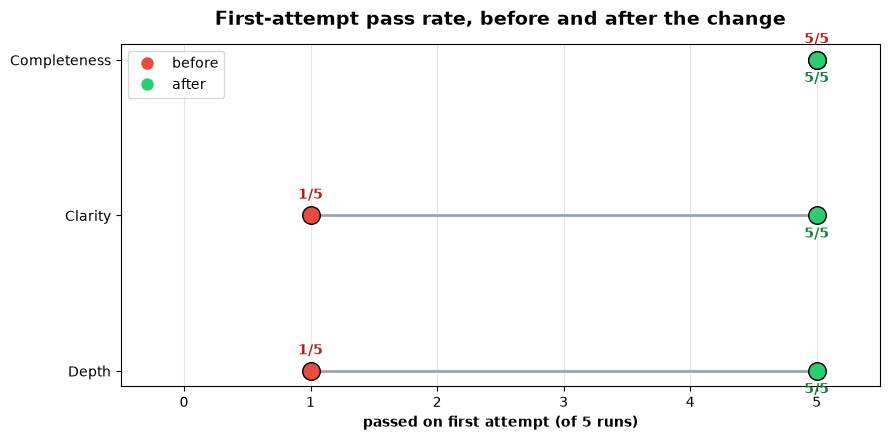

In [12]:
fig = plot_before_after_pass_rates(result)
plt.show()